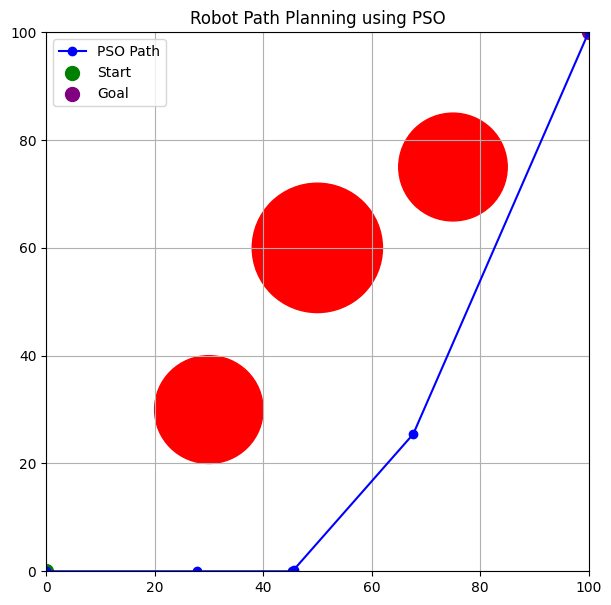

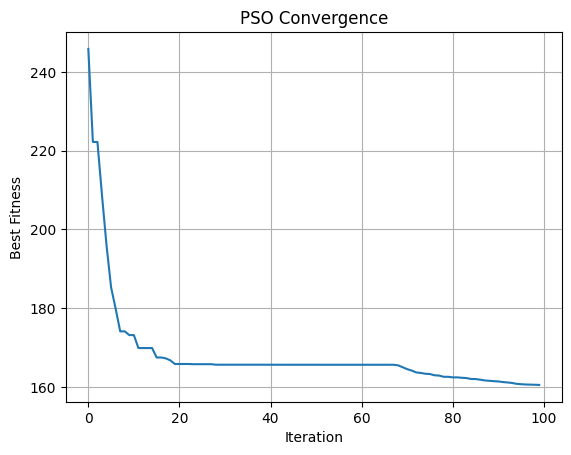

In [2]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

start = np.array([0, 0])
goal = np.array([100, 100])
obstacles = [(30, 30, 10), (50, 60, 12), (75, 75, 10)]

N, iterations, points = 30, 100, 5
dim = points * 2

def fitness(x):
    path = np.vstack([start, x.reshape(-1, 2), goal])
    length = np.linalg.norm(np.diff(path, axis=0), axis=1).sum()
    penalty = 0

    for a, b in zip(path[:-1], path[1:]):
        for ox, oy, r in obstacles:
            c = np.array([ox, oy])
            t = np.clip(np.dot(c-a, b-a) /
                        (np.dot(b-a, b-a) + 1e-9), 0, 1)
            d = np.linalg.norm(a + t*(b-a) - c)
            penalty += 1000 * max(0, r + 3 - d)**2

    return length + penalty

X = np.random.uniform(0, 100, (N, dim))
V = np.zeros_like(X)
P = X.copy()
scores = np.array([fitness(x) for x in X])
G = P[np.argmin(scores)].copy()
history = []

for i in range(iterations):
    w = 0.9 - 0.5*i/iterations

    V = (w*V + 1.5*np.random.rand(N, dim)*(P-X)
         + 1.5*np.random.rand(N, dim)*(G-X))
    X = np.clip(X + V, 0, 100)

    new_scores = np.array([fitness(x) for x in X])
    better = new_scores < scores
    P[better], scores[better] = X[better], new_scores[better]

    G = P[np.argmin(scores)].copy()
    history.append(fitness(G))

path = np.vstack([start, G.reshape(-1, 2), goal])

# Plot path and obstacles
plt.figure(figsize=(7, 7))
for ox, oy, r in obstacles:
    plt.gca().add_patch(plt.Circle((ox, oy), r, color="red"))

plt.plot(path[:, 0], path[:, 1], "b-o", label="PSO Path")
plt.scatter(*start, color="green", s=100, label="Start")
plt.scatter(*goal, color="purple", s=100, label="Goal")
plt.xlim(0, 100)
plt.ylim(0, 100)
plt.grid()
plt.legend()
plt.title("Robot Path Planning using PSO")
plt.show()

plt.plot(history)
plt.xlabel("Iteration")
plt.ylabel("Best Fitness")
plt.title("PSO Convergence")
plt.grid()
plt.show()